In [19]:

from google.colab import files

uploaded = files.upload()


Saving Housing.csv to Housing (1).csv


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [20]:

import os

print(os.listdir())


['.config', 'Housing.csv', '.ipynb_checkpoints', 'Housing (1).csv', 'sample_data']


In [21]:
df = pd.read_csv("Housing.csv")

print("Dataset loaded successfully!")

df.head()


Dataset loaded successfully!


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [22]:

df.head()



,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [23]:

df.tail()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [24]:

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 545
Number of Columns: 13


In [25]:

print("Column Names:")
print(df.columns.tolist())


Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


In [26]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [27]:

df.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [28]:

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [29]:

print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [30]:

df_clean = df.copy()

# Handle missing numerical values
num_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Handle missing categorical values
cat_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for col in cat_cols:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode()
        if not mode_value.empty:
            df_clean[col] = df_clean[col].fillna(
                mode_value[0]
            )

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Data cleaning completed!")
print("New dataset shape:", df_clean.shape)


Data cleaning completed!
New dataset shape: (545, 13)


In [31]:

print("Remaining missing values:")
print(df_clean.isnull().sum().sum())

print("Remaining duplicates:")
print(df_clean.duplicated().sum())


Remaining missing values:
0
Remaining duplicates:
0


In [32]:

# Select input and target columns

X = df_clean[["area"]]

y = df_clean["price"]

print("Input Feature (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())


Input Feature (X):
   area
0  7420
1  8960
2  9960
3  7500
4  7420

Target Variable (y):
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


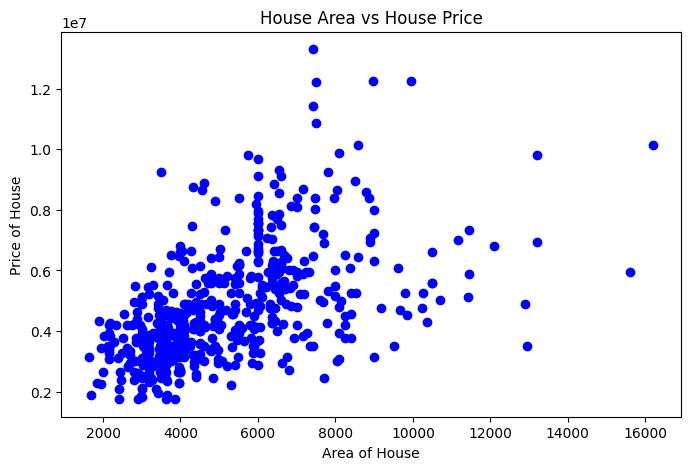

In [33]:

plt.figure(figsize=(8, 5))

plt.scatter(
    X["area"],
    y,
    color="blue"
)

plt.title("House Area vs House Price")
plt.xlabel("Area of House")
plt.ylabel("Price of House")

plt.show()


In [34]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Data: (436, 1)
Testing Data: (109, 1)
Training Target: (436,)
Testing Target: (109,)


In [35]:

# Create Linear Regression model

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [36]:

print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)


Coefficient: 425.72984193878284
Intercept: 2512254.2639593435


In [37]:

print("Linear Regression Equation:")

print(
    f"Price = {model.coef_[0]:.2f} * Area "
    f"+ {model.intercept_:.2f}"
)


Linear Regression Equation:
Price = 425.73 * Area + 2512254.26


In [38]:

y_pred = model.predict(X_test)

print("Predictions generated successfully!")


Predictions generated successfully!


In [39]:

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)


,Actual Price,Predicted Price
0,4060000,5.024060e+06
1,6650000,5.279498e+06
2,3710000,4.232203e+06
3,6440000,4.640903e+06
4,2800000,4.198144e+06
5,4900000,5.373159e+06
6,5250000,6.139473e+06
7,4543000,4.636646e+06
8,2450000,3.891619e+06
9,3353000,3.661725e+06


In [40]:

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)


Mean Absolute Error (MAE): 1474748.1337969352


In [41]:

mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)


Mean Squared Error (MSE): 3675286604768.185


In [42]:

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)


R2 Score: 0.27287851871974644


In [43]:

print("MODEL EVALUATION RESULTS")

print("-----------------------------")

print("MAE:", mae)

print("MSE:", mse)

print("R2 Score:", r2)


MODEL EVALUATION RESULTS
-----------------------------
MAE: 1474748.1337969352
MSE: 3675286604768.185
R2 Score: 0.27287851871974644


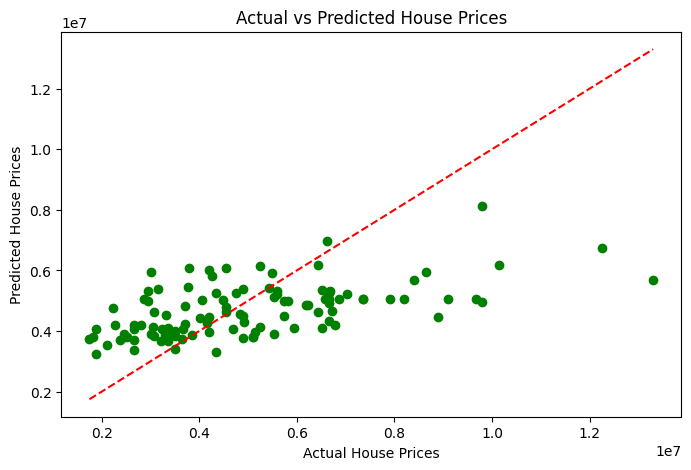

In [44]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    color="green"
)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.show()


In [45]:

# Select a new house area
new_area = X["area"].median()

# Convert into DataFrame
new_house = pd.DataFrame({
    "area": [new_area]
})

# Predict house price
predicted_price = model.predict(new_house)

print("New House Area:", new_area)

print("Predicted House Price:", predicted_price[0])


New House Area: 4600.0
Predicted House Price: 4470611.536877745


In [46]:

comparison.to_csv(
    "house_price_predictions.csv",
    index=False
)

from google.colab import files

files.download("house_price_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>